In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

### Model 1: Item-Based KNN using rating patterns

#### Data Preparation

In [3]:
"""Prepare movie ratings for Item-Based KNN similarity."""

USER_COL = "userId"
ITEM_COL = "movieId"
RATING_COL = "rating"

TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 1 - TRAIN_SIZE - VAL_SIZE
RANDOM_STATE = 42

MIN_MOVIE_RATINGS = 5


def prepare_ratings(ratings):
    """Select the required columns and clean the ratings data."""
    columns = [USER_COL, ITEM_COL, RATING_COL]

    return (
        ratings[columns]
        .dropna()
        .drop_duplicates(subset=[USER_COL, ITEM_COL])
        .copy()
    )


def split_ratings(ratings):
    """Split ratings into training, validation, and testing sets."""
    train_val, test = train_test_split(
        ratings,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

    train, val = train_test_split(
        train_val,
        test_size=VAL_SIZE / (1 - TEST_SIZE),
        random_state=RANDOM_STATE
    )

    return train, val, test


def create_movie_user_matrix(ratings, min_ratings=MIN_MOVIE_RATINGS):
    """Create a sparse movie-user matrix for movies with enough ratings."""
    movie_counts = ratings.groupby(ITEM_COL).size()
    eligible_movies = movie_counts[movie_counts >= min_ratings].index

    filtered = ratings[ratings[ITEM_COL].isin(eligible_movies)]

    matrix = filtered.pivot(
        index=ITEM_COL,
        columns=USER_COL,
        values=RATING_COL
    )

    sparse_matrix = csr_matrix(matrix.fillna(0).to_numpy())

    return matrix, sparse_matrix

In [4]:
ratings_df = pd.read_csv("../data/processed/movielens_ratings_cleaned.csv")
movies_df = pd.read_csv("../data/processed/movielens_movies_cleaned.csv")

print("Ratings:", ratings_df.shape)
print("Movies:", movies_df.shape)

Ratings: (100836, 4)
Movies: (9742, 3)


In [5]:
"""Prepare the ratings and build the movie-user matrix."""

prepared_ratings = prepare_ratings(ratings_df)

train_df, val_df, test_df = split_ratings(prepared_ratings)

movie_user_matrix, movie_user_sparse = create_movie_user_matrix(train_df)

print("Data preparation")
print(f"Training: {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Testing: {len(test_df):,}")
print(f"Movies included in KNN: {movie_user_matrix.shape[0]:,}")
print(f"Users in matrix: {movie_user_matrix.shape[1]:,}")
print(f"Matrix shape: {movie_user_sparse.shape}")

Data preparation
Training: 70,584
Validation: 15,126
Testing: 15,126
Movies included in KNN: 2,963
Users in matrix: 610
Matrix shape: (2963, 610)


#### Baseline Model

In [6]:
"""Build a popularity-based baseline using movie ratings."""

MIN_MOVIE_RATINGS = 5
TOP_N = 10


def fit_popularity_baseline(ratings, min_ratings=MIN_MOVIE_RATINGS):
    """Calculate movie averages and keep movies with enough ratings."""
    movie_stats = (
        ratings.groupby(ITEM_COL)[RATING_COL]
        .agg(avg_rating="mean", rating_count="count")
        .reset_index()
    )

    return movie_stats[
        movie_stats["rating_count"] >= min_ratings
    ].sort_values(
        ["avg_rating", "rating_count"],
        ascending=False
    )


def recommend_popular_movies(movie_stats, movies, n=TOP_N, exclude_movie_id=None):
    """Return the highest-rated movies with their titles."""
    recommendations = movie_stats

    if exclude_movie_id is not None:
        recommendations = recommendations[
            recommendations[ITEM_COL] != exclude_movie_id
        ]

    return (
        recommendations.head(n)
        .merge(
            movies[[ITEM_COL, "title"]],
            on=ITEM_COL,
            how="left"
        )
        [["title", "avg_rating", "rating_count"]]
    )

In [7]:
"""Train the baseline and display the top recommended movies."""

popular_movies = fit_popularity_baseline(train_df)

baseline_recommendations = recommend_popular_movies(
    popular_movies,
    movies_df
)

print(f"Movies eligible for recommendations: {len(popular_movies):,}")

baseline_recommendations

Movies eligible for recommendations: 2,963


,title,avg_rating,rating_count
0,"Three Billboards Outside Ebbing, Missouri (2017)",4.800000,5
1,"Wings of the Dove, The (1997)",4.700000,5
2,Secrets & Lies (1996),4.687500,8
3,Paths of Glory (1957),4.666667,9
4,"Last Picture Show, The (1971)",4.666667,6
5,Five Easy Pieces (1970),4.642857,7
6,Guess Who's Coming to Dinner (1967),4.625000,8
7,Swept Away (Travolti da un insolito destino ne...,4.600000,5
8,Wild Tales (2014),4.600000,5
9,"Streetcar Named Desire, A (1951)",4.500000,13


#### Item-Based KNN

In [8]:
"""Train Item-Based KNN to find movies with similar rating patterns."""

K_NEIGHBORS = 10
SIMILARITY_METRIC = "cosine"


def train_item_knn(movie_matrix):
    """Fit a KNN model using movie rating patterns."""
    model = NearestNeighbors(
        metric=SIMILARITY_METRIC,
        algorithm="brute"
    )

    model.fit(movie_matrix)

    return model


knn_model = train_item_knn(movie_user_sparse)

print("Item-Based KNN trained successfully")

Item-Based KNN trained successfully


In [9]:
"""Find and display movies with similar rating patterns."""

def find_similar_movies(movie_id, model, matrix, sparse_matrix, movies, k=K_NEIGHBORS):
    """Return the K movies most similar to a selected movie."""
    if movie_id not in matrix.index:
        raise ValueError("Movie not found in the KNN training matrix.")

    movie_index = matrix.index.get_loc(movie_id)
    neighbor_count = min(k + 1, len(matrix))

    distances, indices = model.kneighbors(
        sparse_matrix[movie_index],
        n_neighbors=neighbor_count
    )

    neighbors = pd.DataFrame({
        ITEM_COL: matrix.index[indices[0]],
        "similarity": 1 - distances[0]
    })

    neighbors = neighbors[neighbors[ITEM_COL] != movie_id].head(k)

    return (
        neighbors.merge(
            movies[[ITEM_COL, "title"]],
            on=ITEM_COL,
            how="left"
        )
        [["title", "similarity"]]
        .reset_index(drop=True)
    )

In [10]:
"""Display the selected movie and its most similar movies."""

TARGET_MOVIE_ID = 1

target_movie = movies_df.loc[
    movies_df[ITEM_COL] == TARGET_MOVIE_ID, "title"
].iloc[0]

similar_movies = find_similar_movies(
    movie_id=TARGET_MOVIE_ID,
    model=knn_model,
    matrix=movie_user_matrix,
    sparse_matrix=movie_user_sparse,
    movies=movies_df
)

print(f"Movies similar to: {target_movie}\n")

display(similar_movies)

Movies similar to: Toy Story (1995)



,title,similarity
0,"Lion King, The (1994)",0.431171
1,Pulp Fiction (1994),0.424003
2,"Monsters, Inc. (2001)",0.423781
3,Back to the Future (1985),0.420359
4,"Shawshank Redemption, The (1994)",0.417879
5,Shrek (2001),0.411495
6,Independence Day (a.k.a. ID4) (1996),0.408580
7,Star Wars: Episode IV - A New Hope (1977),0.407157
8,Toy Story 2 (1999),0.405639
9,Willy Wonka & the Chocolate Factory (1971),0.403338


#### Evaluate

In [11]:
"""Evaluate movie recommendations using held-out positive ratings."""

TOP_N = 10
MIN_POSITIVE_RATING = 4.0
KNN_CANDIDATES = 100


def get_knn_recommendations(movie_id, seen_movies, n=TOP_N):
    """Recommend similar unseen movies using the trained KNN model."""
    movie_index = movie_user_matrix.index.get_loc(movie_id)

    neighbor_count = min(KNN_CANDIDATES + 1, len(movie_user_matrix))

    distances, indices = knn_model.kneighbors(
        movie_user_sparse[movie_index],
        n_neighbors=neighbor_count
    )

    neighbors = pd.DataFrame({
        ITEM_COL: movie_user_matrix.index[indices[0]],
        "similarity": 1 - distances[0]
    })

    return (
        neighbors[
            ~neighbors[ITEM_COL].isin(seen_movies)
        ]
        .head(n)[ITEM_COL]
        .tolist()
    )


def evaluate_recommender(train, validation, method="knn", n=TOP_N):
    """Measure Recall@N and Hit Rate@N using validation ratings."""
    positive_train = train[train[RATING_COL] >= MIN_POSITIVE_RATING]
    positive_val = validation[validation[RATING_COL] >= MIN_POSITIVE_RATING]

    seen_by_user = train.groupby(USER_COL)[ITEM_COL].apply(set)
    liked_by_user = positive_val.groupby(USER_COL)[ITEM_COL].apply(set)

    hits = 0
    total_liked = 0
    successful_users = 0
    evaluated_users = 0
    total_recommended = 0

    for user_id, user_ratings in positive_train.groupby(USER_COL):
        if user_id not in liked_by_user:
            continue

        seed_movie = user_ratings.sort_values(
            [RATING_COL, ITEM_COL],
            ascending=[False, True]
        )[ITEM_COL].iloc[0]

        if seed_movie not in movie_user_matrix.index:
            continue

        seen_movies = seen_by_user[user_id]
        liked_movies = liked_by_user[user_id]

        if method == "knn":
            recommendations = get_knn_recommendations(
                seed_movie, seen_movies, n
            )
        elif method == "baseline":
            recommendations = (
                popular_movies[
                    ~popular_movies[ITEM_COL].isin(seen_movies)
                ]
                .head(n)[ITEM_COL]
                .tolist()
            )
        else:
            raise ValueError("Method must be 'knn' or 'baseline'.")

        user_hits = len(set(recommendations) & liked_movies)

        hits += user_hits
        total_liked += len(liked_movies)
        successful_users += int(user_hits > 0)
        evaluated_users += 1
        total_recommended += len(recommendations)

    if evaluated_users == 0:
        raise ValueError("No eligible users found for evaluation.")

    return {
        "Recall@10": hits / total_liked,
        "Hit Rate@10": successful_users / evaluated_users,
        "Users Evaluated": evaluated_users,
        "Avg Recommendations": total_recommended / evaluated_users
    }

In [12]:
"""Compare popularity-based and KNN recommendations on validation data."""

baseline_results = evaluate_recommender(
    train_df, val_df, method="baseline"
)

knn_results = evaluate_recommender(
    train_df, val_df, method="knn"
)

results_df = pd.DataFrame(
    [baseline_results, knn_results],
    index=["Popularity Baseline", "Item-Based KNN"]
)

results_df.round(3)

,Recall@10,Hit Rate@10,Users Evaluated,Avg Recommendations
Popularity Baseline,0.002,0.026,579,10.0
Item-Based KNN,0.051,0.401,579,10.0


#### Hyperparameter Tuning.

In [13]:
"""Prepare reusable functions for tuning Item-Based KNN."""

MIN_RATINGS_OPTIONS = [3, 5, 10]
MIN_SHARED_OPTIONS = [1, 3, 5]
CANDIDATE_OPTIONS = [50, 100, 200]

TOP_N = 10
MIN_POSITIVE_RATING = 4.0


def prepare_evaluation_cases(train, validation, eligible_movies):
    """Create fixed user histories and relevant movies for evaluation."""
    positive_train = train[train[RATING_COL] >= MIN_POSITIVE_RATING]
    positive_val = validation[validation[RATING_COL] >= MIN_POSITIVE_RATING]

    seen_by_user = train.groupby(USER_COL)[ITEM_COL].apply(set)
    liked_by_user = positive_val.groupby(USER_COL)[ITEM_COL].apply(set)

    cases = []

    for user_id, ratings in positive_train.groupby(USER_COL):
        if user_id not in liked_by_user:
            continue

        seed = ratings.sort_values(
            [RATING_COL, ITEM_COL],
            ascending=[False, True]
        )[ITEM_COL].iloc[0]

        if seed not in eligible_movies:
            continue

        cases.append({
            "user_id": user_id,
            "seed": seed,
            "seen": seen_by_user[user_id],
            "liked": liked_by_user[user_id]
        })

    return cases


def build_candidate_cache(train, cases, min_ratings, max_candidates):
    """Train KNN and find candidate movies with their shared-user counts."""
    matrix, sparse = create_movie_user_matrix(
        train, min_ratings=min_ratings
    )

    model = train_item_knn(sparse)

    binary = sparse.copy()
    binary.data = np.ones_like(binary.data)

    valid_seeds = sorted({
        case["seed"]
        for case in cases
        if case["seed"] in matrix.index
    })

    cache = {}

    if not valid_seeds:
        return cache

    seed_indices = matrix.index.get_indexer(valid_seeds)
    neighbor_count = min(max_candidates + 1, len(matrix))

    distances, indices = model.kneighbors(
        sparse[seed_indices],
        n_neighbors=neighbor_count
    )

    for seed, seed_index, neighbor_indices in zip(
        valid_seeds, seed_indices, indices
    ):
        shared_counts = (
            binary[neighbor_indices] @ binary[seed_index].T
        ).toarray().ravel()

        cache[seed] = [
            (matrix.index[i], int(shared))
            for i, shared in zip(neighbor_indices, shared_counts)
            if matrix.index[i] != seed
        ]

    return cache


def evaluate_configuration(cases, cache, min_shared, candidates, popular_movies):
    """Evaluate recommendations with fixed user histories."""
    total_hits = 0
    total_liked = 0
    successful_users = 0
    total_recommendations = 0
    fallback_users = 0

    for case in cases:
        seen = case["seen"]
        neighbors = cache.get(case["seed"])

        if neighbors is None:
            fallback_users += 1
            recommendations = (
                popular_movies.loc[
                    ~popular_movies[ITEM_COL].isin(seen),
                    ITEM_COL
                ].head(TOP_N).tolist()
            )
        else:
            recommendations = [
                movie_id
                for movie_id, shared in neighbors[:candidates]
                if shared >= min_shared and movie_id not in seen
            ][:TOP_N]

        hits = len(set(recommendations) & case["liked"])

        total_hits += hits
        total_liked += len(case["liked"])
        successful_users += int(hits > 0)
        total_recommendations += len(recommendations)

    n_users = len(cases)

    return {
        "recall": total_hits / total_liked,
        "hit_rate": successful_users / n_users,
        "avg_recommendations": total_recommendations / n_users,
        "fallback_users": fallback_users,
        "users_evaluated": n_users
    }

In [14]:
"""Compare KNN configurations using the validation dataset."""

evaluation_cases = prepare_evaluation_cases(
    train_df,
    val_df,
    movie_user_matrix.index
)

tuning_results = []

for min_ratings in MIN_RATINGS_OPTIONS:
    candidate_cache = build_candidate_cache(
        train_df,
        evaluation_cases,
        min_ratings,
        max(CANDIDATE_OPTIONS)
    )

    for min_shared in MIN_SHARED_OPTIONS:
        for candidates in CANDIDATE_OPTIONS:
            metrics = evaluate_configuration(
                evaluation_cases,
                candidate_cache,
                min_shared,
                candidates,
                popular_movies
            )

            tuning_results.append({
                "min_movie_ratings": min_ratings,
                "min_shared_users": min_shared,
                "candidates": candidates,
                **metrics
            })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    ["hit_rate", "recall"],
    ascending=False
).reset_index(drop=True)

display(tuning_df.round(3))

,min_movie_ratings,min_shared_users,candidates,recall,hit_rate,avg_recommendations,fallback_users,users_evaluated
0,10,5,200,0.052,0.413,9.964,15,579
1,10,5,100,0.052,0.411,9.934,15,579
2,5,5,200,0.052,0.409,9.701,0,579
3,3,5,200,0.051,0.408,9.667,0,579
4,10,1,100,0.051,0.408,10.000,15,579
5,10,1,200,0.051,0.408,10.000,15,579
6,10,3,100,0.051,0.408,10.000,15,579
7,10,3,200,0.051,0.408,10.000,15,579
8,10,5,50,0.051,0.408,9.876,15,579
9,3,5,100,0.051,0.406,9.553,0,579


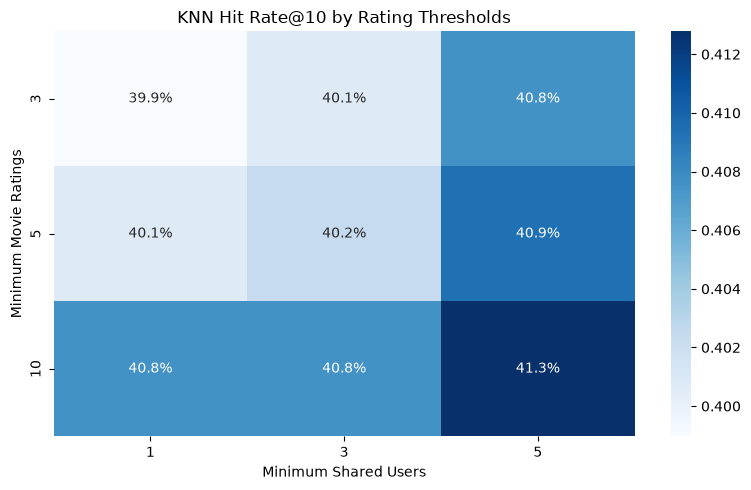

In [15]:
"""Visualize how rating thresholds affect KNN performance."""

heatmap_data = tuning_df[
    tuning_df["candidates"] == max(CANDIDATE_OPTIONS)
].pivot(
    index="min_movie_ratings",
    columns="min_shared_users",
    values="hit_rate"
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1%",
    cmap="Blues"
)

plt.title("KNN Hit Rate@10 by Rating Thresholds")
plt.xlabel("Minimum Shared Users")
plt.ylabel("Minimum Movie Ratings")
plt.tight_layout()
plt.show()

In [16]:
"""Compare our original KNN with the best tuned configuration."""

best_config = tuning_df.iloc[0]

comparison_df = pd.DataFrame({
    "Model": ["Original KNN", "Tuned KNN"],
    "Hit Rate@10": [
        0.401,
        best_config["hit_rate"]
    ],
    "Recall@10": [
        0.051,
        best_config["recall"]
    ]
})

display(comparison_df.round(3))

print("\nBest configuration:")
print(f"Minimum movie ratings: {int(best_config['min_movie_ratings'])}")
print(f"Minimum shared users: {int(best_config['min_shared_users'])}")
print(f"Candidate neighbors: {int(best_config['candidates'])}")
print(f"Average recommendations: {best_config['avg_recommendations']:.2f}")
print(f"Fallback users: {int(best_config['fallback_users'])}")

,Model,Hit Rate@10,Recall@10
0,Original KNN,0.401,0.051
1,Tuned KNN,0.413,0.052



Best configuration:
Minimum movie ratings: 10
Minimum shared users: 5
Candidate neighbors: 200
Average recommendations: 9.96
Fallback users: 15


#### Tuned Item-Based KNN

In [17]:
"""Train the tuned KNN model and recommend similar movies."""

BEST_MIN_MOVIE_RATINGS = 10
BEST_MIN_SHARED_USERS = 5
BEST_CANDIDATES = 200
TOP_N = 10

TARGET_MOVIE_ID = 1


def recommend_tuned_knn(movie_id, model, matrix, sparse, movies, n=TOP_N):
    """Find similar movies that meet the shared-user requirement."""
    if movie_id not in matrix.index:
        raise ValueError("Selected movie is not eligible for KNN.")

    movie_index = matrix.index.get_loc(movie_id)
    neighbor_count = min(BEST_CANDIDATES + 1, len(matrix))

    distances, indices = model.kneighbors(
        sparse[movie_index],
        n_neighbors=neighbor_count
    )

    binary = sparse.copy()
    binary.data = np.ones_like(binary.data)

    neighbor_indices = indices[0]
    shared_counts = (
        binary[neighbor_indices] @ binary[movie_index].T
    ).toarray().ravel()

    recommendations = pd.DataFrame({
        ITEM_COL: matrix.index[neighbor_indices],
        "similarity": 1 - distances[0],
        "shared_users": shared_counts
    })

    recommendations = recommendations[
        (recommendations[ITEM_COL] != movie_id) &
        (recommendations["shared_users"] >= BEST_MIN_SHARED_USERS)
    ].head(n)

    return recommendations.merge(
        movies[[ITEM_COL, "title"]],
        on=ITEM_COL,
        how="left"
    )[["title", "similarity", "shared_users"]].reset_index(drop=True)


tuned_matrix, tuned_sparse = create_movie_user_matrix(
    train_df,
    min_ratings=BEST_MIN_MOVIE_RATINGS
)

tuned_knn = train_item_knn(tuned_sparse)

target_movie = movies_df.loc[
    movies_df[ITEM_COL] == TARGET_MOVIE_ID, "title"
].iloc[0]

recommendations = recommend_tuned_knn(
    TARGET_MOVIE_ID,
    tuned_knn,
    tuned_matrix,
    tuned_sparse,
    movies_df
)

print(f"Movies similar to: {target_movie}")
print(f"Minimum movie ratings: {BEST_MIN_MOVIE_RATINGS}")
print(f"Minimum shared users: {BEST_MIN_SHARED_USERS}")
print(f"Candidate neighbors: {BEST_CANDIDATES}\n")

display(recommendations)

Movies similar to: Toy Story (1995)
Minimum movie ratings: 10
Minimum shared users: 5
Candidate neighbors: 200



,title,similarity,shared_users
0,"Lion King, The (1994)",0.431171,61.0
1,Pulp Fiction (1994),0.424003,83.0
2,"Monsters, Inc. (2001)",0.423781,50.0
3,Back to the Future (1985),0.420359,62.0
4,"Shawshank Redemption, The (1994)",0.417879,80.0
5,Shrek (2001),0.411495,60.0
6,Independence Day (a.k.a. ID4) (1996),0.408580,67.0
7,Star Wars: Episode IV - A New Hope (1977),0.407157,68.0
8,Toy Story 2 (1999),0.405639,42.0
9,Willy Wonka & the Chocolate Factory (1971),0.403338,45.0


### Model 2: Hybrid Item-Based KNN (Ratings + Genres)

In [18]:
"""Build a hybrid model using rating patterns and movie genres."""

from sklearn.preprocessing import normalize

HYBRID_RATING_WEIGHT = 0.70


def fit_hybrid_model(ratings, movies, min_ratings=BEST_MIN_MOVIE_RATINGS):
    """Prepare normalized rating and genre matrices for movie similarity."""
    matrix, sparse = create_movie_user_matrix(ratings, min_ratings)

    genres = (
        movies.set_index(ITEM_COL)["genres"]
        .reindex(matrix.index)
        .fillna("")
        .str.get_dummies(sep="|")
    )

    rating_vectors = normalize(sparse)
    genre_vectors = normalize(csr_matrix(genres.to_numpy()))

    binary = sparse.copy()
    binary.data = np.ones_like(binary.data)

    return matrix, rating_vectors, genre_vectors, binary


def find_hybrid_neighbors(movie_id, hybrid_model, weight, candidates):
    """Find similar movies using weighted rating and genre similarities."""
    matrix, rating_vectors, genre_vectors, binary = hybrid_model

    if movie_id not in matrix.index:
        return []

    movie_index = matrix.index.get_loc(movie_id)

    rating_similarity = (
        rating_vectors @ rating_vectors[movie_index].T
    ).toarray().ravel()

    genre_similarity = (
        genre_vectors @ genre_vectors[movie_index].T
    ).toarray().ravel()

    combined_similarity = (
        weight * rating_similarity
        + (1 - weight) * genre_similarity
    )

    combined_similarity[movie_index] = -np.inf

    neighbor_indices = np.argsort(
        -combined_similarity, kind="stable"
    )[:candidates]

    shared_counts = (
        binary[neighbor_indices] @ binary[movie_index].T
    ).toarray().ravel()

    return [
        (matrix.index[i], int(shared), combined_similarity[i])
        for i, shared in zip(neighbor_indices, shared_counts)
    ]

#### Test the hybrid recommendations

In [19]:
"""Train the hybrid model and display similar movies."""

TARGET_MOVIE_ID = 1

hybrid_model = fit_hybrid_model(train_df, movies_df)

neighbors = find_hybrid_neighbors(
    TARGET_MOVIE_ID,
    hybrid_model,
    HYBRID_RATING_WEIGHT,
    BEST_CANDIDATES
)

recommendations = pd.DataFrame(
    neighbors,
    columns=[ITEM_COL, "shared_users", "similarity"]
)

recommendations = (
    recommendations[
        recommendations["shared_users"] >= BEST_MIN_SHARED_USERS
    ]
    .head(TOP_N)
    .merge(movies_df[[ITEM_COL, "title"]], on=ITEM_COL)
    [["title", "similarity", "shared_users"]]
)

target_title = movies_df.loc[
    movies_df[ITEM_COL] == TARGET_MOVIE_ID, "title"
].iloc[0]

print(f"Movies similar to: {target_title}")
print(f"Rating weight: {HYBRID_RATING_WEIGHT:.0%}")
print(f"Genre weight: {1 - HYBRID_RATING_WEIGHT:.0%}")

display(recommendations)

Movies similar to: Toy Story (1995)
Rating weight: 70%
Genre weight: 30%


,title,similarity,shared_users
0,"Monsters, Inc. (2001)",0.596647,50
1,Toy Story 2 (1999),0.583947,42
2,Shrek (2001),0.561908,60
3,Finding Nemo (2003),0.535911,48
4,Antz (1998),0.515525,22
5,Ice Age (2002),0.513279,32
6,Toy Story 3 (2010),0.510231,26
7,Harry Potter and the Sorcerer's Stone (a.k.a. ...,0.503184,49
8,Aladdin (1992),0.502582,56
9,"Emperor's New Groove, The (2000)",0.502536,21


#### Tune genre importance and compare models

In [20]:
"""Evaluate different hybrid weights against ratings-only KNN."""

RATING_WEIGHTS = [0.3, 0.5, 0.7, 0.9]

rating_cache = build_candidate_cache(
    train_df,
    evaluation_cases,
    BEST_MIN_MOVIE_RATINGS,
    BEST_CANDIDATES
)

rating_results = evaluate_configuration(
    evaluation_cases,
    rating_cache,
    BEST_MIN_SHARED_USERS,
    BEST_CANDIDATES,
    popular_movies
)

hybrid_results = []

for weight in RATING_WEIGHTS:
    hybrid_cache = {}

    for case in evaluation_cases:
        seed = case["seed"]

        if seed not in hybrid_cache:
            neighbors = find_hybrid_neighbors(
                seed, hybrid_model, weight, BEST_CANDIDATES
            )

            hybrid_cache[seed] = [
                (movie_id, shared)
                for movie_id, shared, similarity in neighbors
            ]

    metrics = evaluate_configuration(
        evaluation_cases,
        hybrid_cache,
        BEST_MIN_SHARED_USERS,
        BEST_CANDIDATES,
        popular_movies
    )

    hybrid_results.append({
        "rating_weight": weight,
        "genre_weight": 1 - weight,
        **metrics
    })

hybrid_results_df = pd.DataFrame(hybrid_results)

display(
    hybrid_results_df[
        ["rating_weight", "genre_weight", "recall",
         "hit_rate", "avg_recommendations"]
    ].round(3)
)

,rating_weight,genre_weight,recall,hit_rate,avg_recommendations
0,0.3,0.7,0.021,0.206,9.608
1,0.5,0.5,0.024,0.240,9.615
2,0.7,0.3,0.035,0.323,9.667
3,0.9,0.1,0.050,0.409,9.693


In [23]:
"""Run the best Hybrid KNN model and display similar movies."""

BEST_HYBRID_WEIGHT = 0.90
TARGET_MOVIE_ID = 1

hybrid_model = fit_hybrid_model(
    train_df,
    movies_df,
    min_ratings=BEST_MIN_MOVIE_RATINGS
)

neighbors = find_hybrid_neighbors(
    TARGET_MOVIE_ID,
    hybrid_model,
    BEST_HYBRID_WEIGHT,
    BEST_CANDIDATES
)

recommendations = pd.DataFrame(
    neighbors,
    columns=[ITEM_COL, "shared_users", "similarity"]
)

recommendations = (
    recommendations[
        recommendations["shared_users"] >= BEST_MIN_SHARED_USERS
    ]
    .head(TOP_N)
    .merge(movies_df[[ITEM_COL, "title"]], on=ITEM_COL, how="left")
    [["title", "similarity", "shared_users"]]
    .reset_index(drop=True)
)

target_title = movies_df.loc[
    movies_df[ITEM_COL] == TARGET_MOVIE_ID, "title"
].iloc[0]

print(f"Movies similar to: {target_title}")
print(f"Rating weight: {BEST_HYBRID_WEIGHT:.0%}")
print(f"Genre weight: {1 - BEST_HYBRID_WEIGHT:.0%}")
print(f"Minimum movie ratings: {BEST_MIN_MOVIE_RATINGS}")
print(f"Minimum shared users: {BEST_MIN_SHARED_USERS}")
print(f"Candidate neighbors: {BEST_CANDIDATES}")

display(recommendations)

Movies similar to: Toy Story (1995)
Rating weight: 90%
Genre weight: 10%
Minimum movie ratings: 10
Minimum shared users: 5
Candidate neighbors: 200


,title,similarity,shared_users
0,"Monsters, Inc. (2001)",0.481403,50
1,Toy Story 2 (1999),0.465075,42
2,Shrek (2001),0.461633,60
3,"Lion King, The (1994)",0.442826,61
4,Finding Nemo (2003),0.433478,48
5,Willy Wonka & the Chocolate Factory (1971),0.430086,45
6,Back to the Future (1985),0.429963,62
7,Harry Potter and the Sorcerer's Stone (a.k.a. ...,0.425638,49
8,Aladdin (1992),0.417606,56
9,Pirates of the Caribbean: The Curse of the Bla...,0.416614,52


#### Compare Both Models

In [25]:
"""Compare the performance and recommendations of both KNN models."""

best_hybrid = hybrid_results_df.loc[
    hybrid_results_df["hit_rate"].idxmax()
]

comparison_df = pd.DataFrame({
    "Model": ["Ratings-Only KNN", "Hybrid KNN"],
    "Recall@10": [
        rating_results["recall"],
        best_hybrid["recall"]
    ],
    "Hit Rate@10": [
        rating_results["hit_rate"],
        best_hybrid["hit_rate"]
    ]
})

print("Model Performance Comparison")
display(comparison_df.round(3))


ratings_movies = recommend_tuned_knn(
    TARGET_MOVIE_ID,
    tuned_knn,
    tuned_matrix,
    tuned_sparse,
    movies_df
)

hybrid_movies = recommendations

movie_comparison = pd.DataFrame({
    "Ratings-Only KNN": ratings_movies["title"],
    "Hybrid KNN": hybrid_movies["title"]
})

target_title = movies_df.loc[
    movies_df[ITEM_COL] == TARGET_MOVIE_ID, "title"
].iloc[0]

print(f"\nMovies similar to: {target_title}")
display(movie_comparison)

Model Performance Comparison


,Model,Recall@10,Hit Rate@10
0,Ratings-Only KNN,0.052,0.413
1,Hybrid KNN,0.050,0.409



Movies similar to: Toy Story (1995)


,Ratings-Only KNN,Hybrid KNN
0,"Lion King, The (1994)","Monsters, Inc. (2001)"
1,Pulp Fiction (1994),Toy Story 2 (1999)
2,"Monsters, Inc. (2001)",Shrek (2001)
3,Back to the Future (1985),"Lion King, The (1994)"
4,"Shawshank Redemption, The (1994)",Finding Nemo (2003)
5,Shrek (2001),Willy Wonka & the Chocolate Factory (1971)
6,Independence Day (a.k.a. ID4) (1996),Back to the Future (1985)
7,Star Wars: Episode IV - A New Hope (1977),Harry Potter and the Sorcerer's Stone (a.k.a. ...
8,Toy Story 2 (1999),Aladdin (1992)
9,Willy Wonka & the Chocolate Factory (1971),Pirates of the Caribbean: The Curse of the Bla...
